# N2_3_TRI — Previsão de notas

Objetivo: estimar a nota de prova de um estudante usando informações sobre estudo e vida escolar.

O dataframe contém fatores estudantis e notas. O enunciado informa que os dados são sintéticos. Por isso, os resultados podem não representar estudantes reais e não mostram causa e efeito.

Eis a questão: podemos estimar a nota de um estudante com base em seus hábitos de estudo, frequência e outras características?

As variáveis de entrada são Hours_Studied (horas de estudo), Attendance (frequência), Sleep_Hours (horas de sono), Previous_Scores (notas anteriores), Tutoring_Sessions (sessões de reforço), Physical_Activity (atividade física) e Motivation_Level (motivação).

A variável que queremos prever é Exam_Score, a nota da prova. Como a nota é um número, usamos Regressão, não Classificação. O modelo escolhido é Regressão Linear.

## Inspeção dos dados

Nesta etapa, carregamos o arquivo e verificamos algumas linhas, o tamanho da tabela, os tipos de dados, as estatísticas, os valores ausentes, as duplicatas e as categorias de motivação.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df_original = pd.read_csv("StudentPerformanceFactors.csv")
print(df_original.head().to_string())
print("Dimensoes:", df_original.shape)
df_original.info()
print(df_original.describe().to_string())
print("Valores ausentes:\n", df_original.isnull().sum().to_string())
print("Duplicatas:", df_original.duplicated().sum())
print("Niveis de motivacao:", sorted(df_original["Motivation_Level"].dropna().unique()))

   Hours_Studied  Attendance Parental_Involvement Access_to_Resources Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level Internet_Access  Tutoring_Sessions Family_Income Teacher_Quality School_Type Peer_Influence  Physical_Activity Learning_Disabilities Parental_Education_Level Distance_from_Home  Gender  Exam_Score
0             23          84                  Low                High                         No            7               73              Low             Yes                  0           Low          Medium      Public       Positive                  3                    No              High School               Near    Male          67
1             19          64                  Low              Medium                         No            8               59              Low             Yes                  2        Medium          Medium      Public       Negative                  4                    No                  College           Modera

## Preparação dos dados

In [ ]:
colunas_X = ["Hours_Studied", "Attendance", "Sleep_Hours", "Previous_Scores", "Tutoring_Sessions", "Physical_Activity", "Motivation_Level"]
alvo = "Exam_Score"
df = df_original.drop_duplicates().copy()
df = df[colunas_X + [alvo]].copy()

for coluna in colunas_X[:6] + [alvo]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")
print("Ausentes:\n", df.isnull().sum().to_string())
print("Frequencia fora de 0 a 100:", int((~df["Attendance"].between(0, 100)).sum()))
print("Horas ou sessoes negativas:", int((df[["Hours_Studied", "Sleep_Hours", "Tutoring_Sessions", "Physical_Activity"]] < 0).sum().sum()))

df = df.dropna(subset=[alvo])
X = df[colunas_X].copy()
y = df[alvo].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for coluna in colunas_X[:6]:
    mediana = X_train[coluna].median()
    X_train[coluna] = X_train[coluna].fillna(mediana)
    X_test[coluna] = X_test[coluna].fillna(mediana)

moda = X_train["Motivation_Level"].mode()[0]
X_train["Motivation_Level"] = X_train["Motivation_Level"].fillna(moda)
X_test["Motivation_Level"] = X_test["Motivation_Level"].fillna(moda)
mapa_motivacao = {"Low": 0, "Medium": 1, "High": 2}
X_train["Motivation_Level"] = X_train["Motivation_Level"].map(mapa_motivacao)
X_test["Motivation_Level"] = X_test["Motivation_Level"].map(mapa_motivacao)
print("Linhas de treino:", len(X_train), "| Linhas de teste:", len(X_test))

Ausentes:
 Hours_Studied        0
Attendance           0
Sleep_Hours          0
Previous_Scores      0
Tutoring_Sessions    0
Physical_Activity    0
Motivation_Level     0
Exam_Score           0
Frequencia fora de 0 a 100: 0
Horas ou sessoes negativas: 0
Linhas de treino: 5285 | Linhas de teste: 1322


## Treinamento e coeficientes

In [ ]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)
print("Intercepto:", modelo.intercept_)

coeficientes = pd.DataFrame({"Variavel": colunas_X, "Coeficiente": modelo.coef_})
coeficientes = coeficientes.sort_values("Coeficiente", key=abs, ascending=False)
print(coeficientes.to_string(index=False))

Intercepto: 40.44266718256439
         Variavel  Coeficiente
 Motivation_Level     0.519700
Tutoring_Sessions     0.509308
    Hours_Studied     0.290062
       Attendance     0.199244
Physical_Activity     0.158370
  Previous_Scores     0.048072
      Sleep_Hours    -0.034789


## Avaliação

In [ ]:
y_previsto = modelo.predict(X_test)
r2 = r2_score(y_test, y_previsto)
mae = mean_absolute_error(y_test, y_previsto)
rmse = np.sqrt(mean_squared_error(y_test, y_previsto))
print(f"R2: {r2:.4f}")
print(f"MAE: {mae:.4f} pontos")
print(f"RMSE: {rmse:.4f} pontos")

R2: 0.6516
MAE: 1.2379 pontos
RMSE: 2.2193 pontos


## Gráfico 1 — Notas reais e previstas

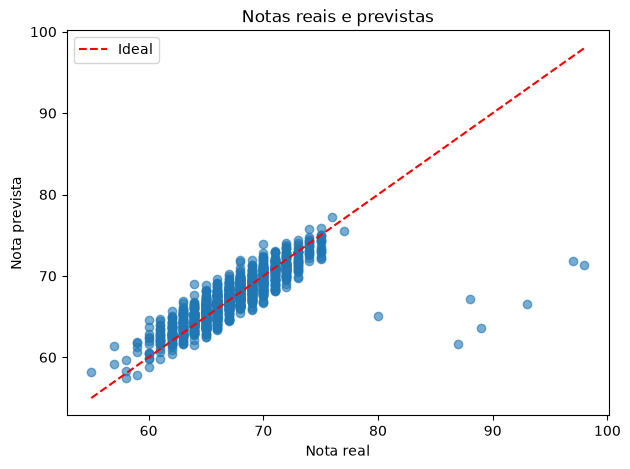

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_previsto, alpha=0.6)
menor = min(y_test.min(), y_previsto.min())
maior = max(y_test.max(), y_previsto.max())
plt.plot([menor, maior], [menor, maior], "r--", label="Ideal")
plt.xlabel("Nota real")
plt.ylabel("Nota prevista")
plt.title("Notas reais e previstas")
plt.legend()
plt.show()

Gráfico 2 — Erros das previsões

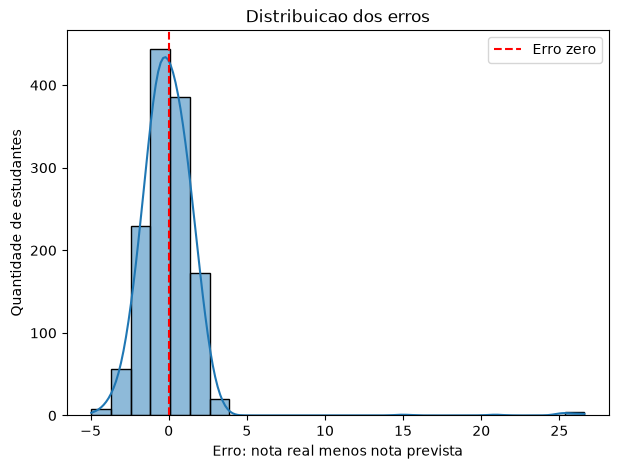

In [11]:
residuos = y_test.to_numpy() - y_previsto
plt.figure(figsize=(7, 5))
sns.histplot(residuos, bins=25, kde=True)
plt.axvline(0, color="red", linestyle="--", label="Erro zero")
plt.xlabel("Erro: nota real menos nota prevista")
plt.ylabel("Quantidade de estudantes")
plt.title("Distribuicao dos erros")
plt.legend()
plt.show()

## Simulador

In [ ]:
print("Informe os dados do estudante:")
estudante = {
    "Hours_Studied": float(input("Horas de estudo: ")),
    "Attendance": float(input("Frequencia (0 a 100): ")),
    "Sleep_Hours": float(input("Horas de sono: ")),
    "Previous_Scores": float(input("Notas anteriores: ")),
    "Tutoring_Sessions": float(input("Sessoes de reforco: ")),
    "Physical_Activity": float(input("Horas de atividade fisica: "))
}

while True:
    motivacao = input("Motivacao (Low, Medium ou High): ").strip().title()
    if motivacao in mapa_motivacao:
        break
    print("Escolha Low, Medium ou High.")

estudante["Motivation_Level"] = mapa_motivacao[motivacao]
estudante = pd.DataFrame([estudante], columns=colunas_X)
nota = modelo.predict(estudante)[0]
if nota > 100:
    nota = 100
print(f"Nota estimada: {nota} pontos.")

Informe os dados do estudante:
Nota estimada: 63.81564171750604 pontos.


## Limitações

Os dados são sintéticos e podem não representar estudantes reais. O arquivo também não inclui todos os fatores que podem afetar as notas, como saúde, renda, qualidade do ensino, apoio familiar e estado emocional.

## Conclusão

Neste projeto, verificamos os dados, escolhemos as variáveis solicitadas, dividimos os dados em treino e teste e treinamos uma Regressão Linear. As métricas e os gráficos mostram como o modelo se saiu nesta amostra sintética.

Os resultados não garantem previsões confiáveis para estudantes reais. Como próximos passos, seria útil usar dados reais e comparar outras formas simples de preparar os dados e treinar modelos.